Practice 1 - Notebook 1

# PCA with scikit-learn — Exercise 1

## Weakly correlated features

In this exercise, change the relationship between the two toy features from `0.6 * x1` to `0.1 * x1`, then rerun Part 1. We will compare the variance explained by PC1 and the reconstruction error when only PC1 is kept.

**Workflow:** create the data, fit PCA, inspect the components, transform the data, reconstruct it with one component, and measure the information lost.

## Cell 1 — Import the Libraries

Import NumPy for data generation, Matplotlib for plots, and PCA from scikit-learn.

In [1]:
# General tools for data generation and plotting
import numpy as np
import matplotlib.pyplot as plt

# PCA model
from sklearn.decomposition import PCA

## Cell 2 — Generate the Toy Dataset

Create 50 observations with two features. The coefficient is now `0.1`, so the features move together much less than they did with `0.6`. The random seed stays at `42` so the experiment is reproducible.

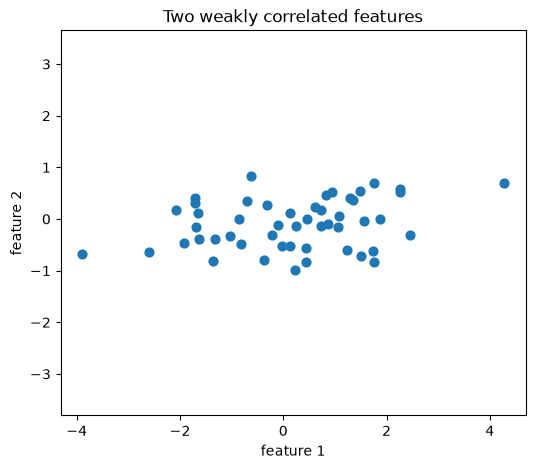

In [2]:
# Generate the same first feature as in the original Part 1
rng = np.random.default_rng(42)
x1 = rng.normal(0, 2, 50)

# Reduce the relationship between the two features from 0.6 to 0.1
x2 = 0.1 * x1 + rng.normal(0, 0.6, 50)

# Combine the two features into one matrix
X_toy = np.column_stack([x1, x2])

# Plot the two features
plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40)
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Two weakly correlated features")
plt.axis("equal")
plt.show()

## Cell 3 — Fit PCA and Check Explained Variance

Fit PCA to both features. `components_` gives the component directions, and `explained_variance_ratio_` gives the share of total variance explained by each component.

In [3]:
# Fit PCA using both components
pca_toy = PCA()
pca_toy.fit(X_toy)

# Display the component directions and their variance shares
print("PC1 direction:", pca_toy.components_[0].round(3))
print("PC2 direction:", pca_toy.components_[1].round(3))
print("explained_variance_ratio_:", pca_toy.explained_variance_ratio_.round(3))

PC1 direction: [0.995 0.098]
PC2 direction: [-0.098  0.995]
explained_variance_ratio_: [0.919 0.081]


## Cell 4 — Plot the Principal Component Directions

Draw PC1 and PC2 on the original data. The arrow lengths represent the spread along each component.

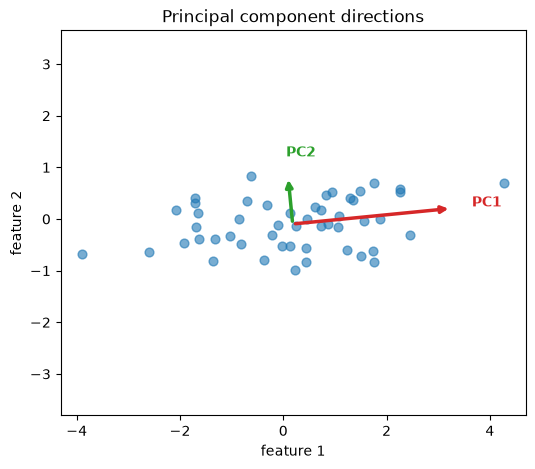

In [4]:
# Plot the observations and the two principal component directions
plt.figure(figsize=(6, 5))
plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40, alpha=0.6)
center = pca_toy.mean_

for comp, var, color, name in zip(
    pca_toy.components_,
    pca_toy.explained_variance_,
    ["tab:red", "tab:green"],
    ["PC1", "PC2"]
):
    end = center + comp * 2 * np.sqrt(var)
    plt.annotate(
        "", xy=end, xytext=center,
        arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5)
    )
    plt.text(*(end + comp * 0.4), name, color=color, fontweight="bold")

plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Principal component directions")
plt.axis("equal")
plt.show()

## Cell 5 — Transform the Data into PCA Coordinates

Use `transform` to represent each observation using PC1 and PC2. Both components are kept here, so no dimensional information is removed yet.

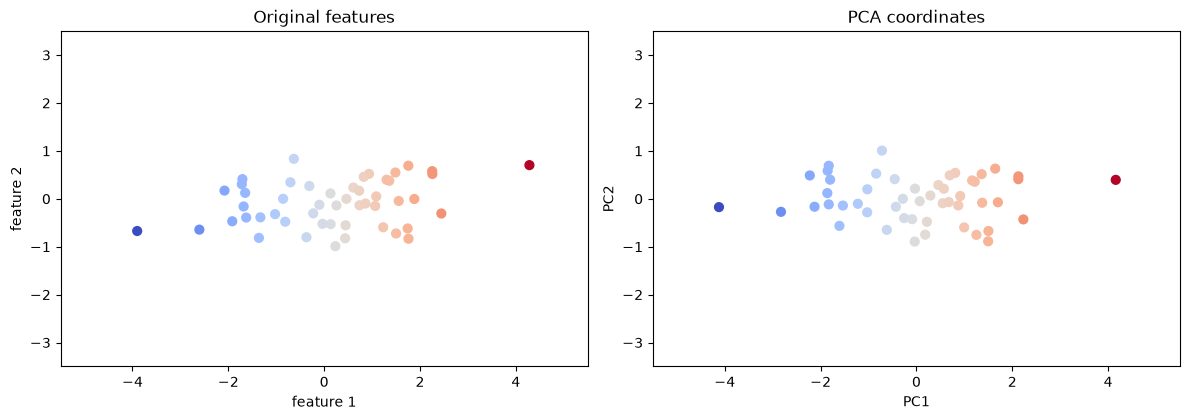

In [5]:
# Transform the original data into the principal component coordinates
X_toy_pca = pca_toy.transform(X_toy)

# Compare the original coordinates with the PCA coordinates
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].scatter(X_toy[:, 0], X_toy[:, 1], s=40, c=X_toy_pca[:, 0], cmap="coolwarm")
axes[0].set_xlabel("feature 1")
axes[0].set_ylabel("feature 2")
axes[0].set_title("Original features")

axes[1].scatter(X_toy_pca[:, 0], X_toy_pca[:, 1], s=40, c=X_toy_pca[:, 0], cmap="coolwarm")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")
axes[1].set_title("PCA coordinates")

for ax in axes:
    ax.set_xlim(-5.5, 5.5)
    ax.set_ylim(-3.5, 3.5)
    ax.set_aspect("equal")

plt.tight_layout()
plt.show()

## Cell 6 — Keep Only PC1

Fit a PCA model with one component. This reduces the data from two features to one component.

In [6]:
# Keep only the first principal component
pca_1 = PCA(n_components=1)
X_1d = pca_1.fit_transform(X_toy)

# Show the change in shape
print(X_toy.shape, "->", X_1d.shape)

(50, 2) -> (50, 1)


## Cell 7 — Reconstruct the Data from PC1

Use `inverse_transform` to return the one-component data to two-feature space. The reconstructed points lie on the PC1 line; the gray segments show the information that was lost.

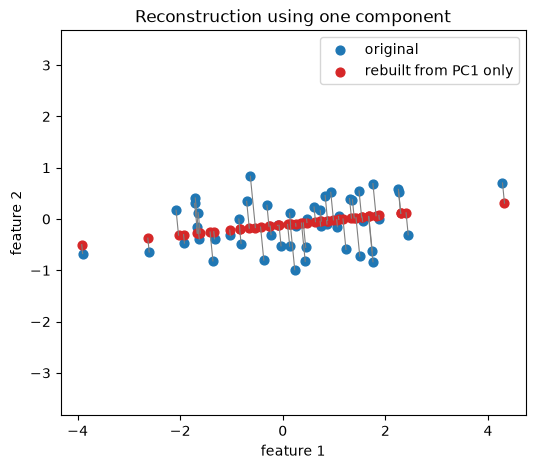

In [7]:
# Reconstruct the two-feature data from PC1 only
X_back_toy = pca_1.inverse_transform(X_1d)

# Plot original and reconstructed observations
plt.figure(figsize=(6, 5))
for original, rebuilt in zip(X_toy, X_back_toy):
    plt.plot(*zip(original, rebuilt), color="gray", lw=0.8)

plt.scatter(X_toy[:, 0], X_toy[:, 1], s=40, label="original")
plt.scatter(X_back_toy[:, 0], X_back_toy[:, 1], s=40, color="tab:red", label="rebuilt from PC1 only")
plt.xlabel("feature 1")
plt.ylabel("feature 2")
plt.title("Reconstruction using one component")
plt.legend()
plt.axis("equal")
plt.show()

## Cell 8 — Measure the Reconstruction Error

Calculate the mean squared reconstruction distance and compare it with the total spread. The fraction of spread lost should match PC2's explained variance ratio, apart from rounding.

In [8]:
# Calculate the mean squared reconstruction error
error_toy = ((X_toy - X_back_toy) ** 2).sum(axis=1).mean()

# Calculate the total spread around the feature means
total_spread = ((X_toy - X_toy.mean(axis=0)) ** 2).sum(axis=1).mean()

# Compare the lost share with PC2's variance share
share_lost = error_toy / total_spread
print("mean squared reconstruction error:", round(error_toy, 3))
print("share of the spread lost:          ", round(share_lost, 3))
print("PC2's explained variance ratio:    ", round(pca_toy.explained_variance_ratio_[1], 3))

mean squared reconstruction error: 0.205
share of the spread lost:           0.081
PC2's explained variance ratio:     0.081


## Cell 9 — Exercise 1: Answer

With the coefficient reduced from `0.6` to `0.1`, the features move together less. **PC1's share of the variance decreases**, while the reconstruction error from keeping only PC1 increases.

For this run, PC1 explains about **91.9%** of the variance, compared with about **95.5%** in the original version. The share of spread lost rises from about **4.5%** to about **8.1%**. The mean squared reconstruction error rises from about **0.151** to about **0.205**.

This happens because the weaker relationship makes the data less concentrated along one direction. PC2 captures a larger share of the variation, so removing it loses more information.